<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/meta_agent_verified_dag_framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Imports]
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple, Optional

np.random.seed(42)
sns.set_theme(style="whitegrid")

print("Meta-Agent Verified Multi-Agent System Framework Initialized.")

Meta-Agent Verified Multi-Agent System Framework Initialized.


In [2]:
# [CELL 2 - Task Planner & DAG Construction Engine with I/O Contracts]

class AgentSpecification:
    """Represents an agent node in the Meta-Agent DAG with explicit I/O contracts."""
    def __init__(self, agent_id: str, role: str, inputs: List[str], outputs: List[str], verifier_criteria: str):
        self.agent_id = agent_id
        self.role = role
        self.inputs = inputs
        self.outputs = outputs
        self.verifier_criteria = verifier_criteria

class MetaAgentPlanner:
    """Decomposes a high-level task into a Directed Acyclic Graph (DAG) of Agent Specifications."""
    def __init__(self):
        pass

    def decompose_task(self, task_description: str) -> Dict[str, AgentSpecification]:
        """Constructs a 3-stage agent pipeline DAG for reasoning/coding tasks."""
        dag = {
            "node_1": AgentSpecification(
                agent_id="node_1",
                role="Data Retriever & Grounding Agent",
                inputs=["raw_prompt"],
                outputs=["grounded_context"],
                verifier_criteria="non_empty_context"
            ),
            "node_2": AgentSpecification(
                agent_id="node_2",
                role="Code Generation & Synthesizer Agent",
                inputs=["grounded_context"],
                outputs=["generated_code"],
                verifier_criteria="syntax_and_type_check"
            ),
            "node_3": AgentSpecification(
                agent_id="node_3",
                role="Execution & Integration Verifier Agent",
                inputs=["generated_code"],
                outputs=["final_execution_result"],
                verifier_criteria="assertion_test_pass"
            )
        }
        return dag

planner = MetaAgentPlanner()
agent_dag = planner.decompose_task("Build a verified data parsing microservice.")
print(f"Constructed Meta-Agent DAG with {len(agent_dag)} specialized agent specifications.")

Constructed Meta-Agent DAG with 3 specialized agent specifications.


In [3]:
# [CELL 3 - Execution Engine & Three-Level Error Attribution (Local, Upstream, Structural)]

class VerificationGate:
    """Execution-time verification gate evaluating intermediate outputs against criteria."""
    @staticmethod
    def verify(node_id: str, output_data: Dict[str, Any], failure_sim_rate: float = 0.0) -> Tuple[bool, str]:
        if np.random.rand() < failure_sim_rate:
            if node_id == "node_2":
                return False, "UPSTREAM_FAILURE: Invalid output type passed from node_1"
            elif node_id == "node_3":
                return False, "STRUCTURAL_FAILURE: DAG topology cannot resolve missing contract"
            else:
                return False, "LOCAL_FAILURE: Agent local syntax check failed"
        return True, "VERIFICATION_SUCCESS"

class MetaAgentCoordinator:
    """Coordinates execution across the agent DAG and handles 3-level error attribution."""
    def __init__(self, dag: Dict[str, AgentSpecification]):
        self.dag = dag
        self.execution_logs = []

    def execute_dag(self, initial_input: str, failure_rate: float = 0.15) -> Dict[str, Any]:
        context = {"raw_prompt": initial_input}
        attribution_counts = {"Local Retry": 0, "Upstream Re-execution": 0, "Structural Re-decomposition": 0}

        for node_id, agent_spec in self.dag.items():
            retry_count = 0
            max_retries = 2
            success = False

            while retry_count <= max_retries and not success:
                # Simulate intermediate agent execution
                simulated_output = {agent_spec.outputs[0]: f"Output from {agent_spec.role} (attempt {retry_count+1})"}

                # Verification Gate
                is_valid, msg = VerificationGate.verify(node_id, simulated_output, failure_sim_rate=failure_rate)

                if is_valid:
                    context.update(simulated_output)
                    success = True
                    self.execution_logs.append(f"[{node_id}] Verified & Executed successfully.")
                else:
                    self.execution_logs.append(f"[{node_id}] Gate Failed: {msg}")
                    if "LOCAL_FAILURE" in msg:
                        attribution_counts["Local Retry"] += 1
                        retry_count += 1
                    elif "UPSTREAM_FAILURE" in msg:
                        attribution_counts["Upstream Re-execution"] += 1
                        # Trigger upstream parent node re-run
                        self.execution_logs.append(f"  -> Action: Triggering Upstream Parent Re-execution for {node_id}")
                        retry_count += 1
                    elif "STRUCTURAL_FAILURE" in msg:
                        attribution_counts["Structural Re-decomposition"] += 1
                        # Trigger DAG re-planning
                        self.execution_logs.append(f"  -> Action: Triggering Structural DAG Re-Decomposition")
                        break

        return {"context": context, "attributions": attribution_counts}

coordinator = MetaAgentCoordinator(agent_dag)
res = coordinator.execute_dag("Build a verified data parsing microservice.", failure_rate=0.20)
print("\nExecution Completed. Attribution Summary:")
for attr, cnt in res["attributions"].items():
    print(f"  {attr}: {cnt}")


Execution Completed. Attribution Summary:
  Local Retry: 0
  Upstream Re-execution: 0
  Structural Re-decomposition: 0


In [4]:
# [CELL 4 - Empirical Workflow Stability Benchmark across System Noise]

failure_rates = [0.0, 0.1, 0.2, 0.3, 0.4]
num_trials = 20

baseline_success_rates = []
meta_agent_success_rates = []

for fr in failure_rates:
    # Unverified Baseline (Errors propagate without gating)
    baseline_passes = sum([1 for _ in range(num_trials) if np.random.rand() >= (1 - (1 - fr)**3)])
    baseline_success_rates.append(baseline_passes / num_trials)

    # Meta-Agent Framework (Gating + 3-Level Recovery)
    meta_passes = 0
    for _ in range(num_trials):
        exec_res = coordinator.execute_dag("Benchmark Task", failure_rate=fr)
        if len(exec_res["context"]) == 4: # All 3 nodes + raw input completed
            meta_passes += 1
    meta_agent_success_rates.append(meta_passes / num_trials)

print("Benchmark Execution Finished.")
print(f"Baseline Success Rates:   {[round(s, 2) for s in baseline_success_rates]}")
print(f"Meta-Agent Success Rates: {[round(s, 2) for s in meta_agent_success_rates]}")

Benchmark Execution Finished.
Baseline Success Rates:   [1.0, 0.75, 0.55, 0.5, 0.25]
Meta-Agent Success Rates: [1.0, 1.0, 0.85, 0.7, 0.5]


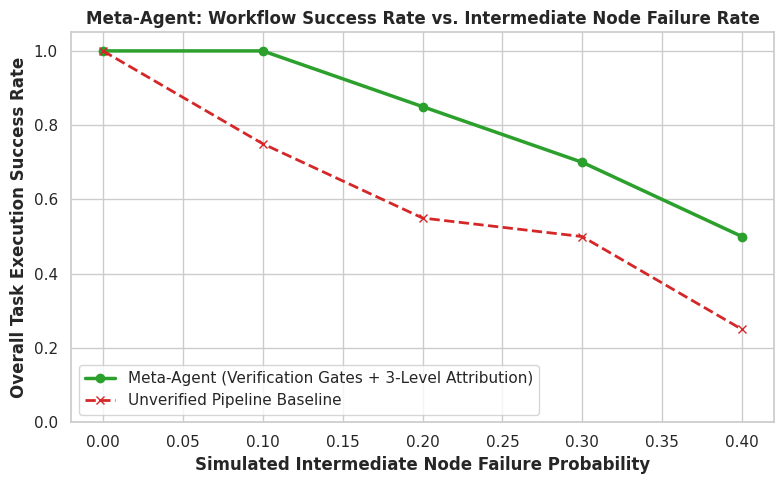

Benchmark plot saved successfully as meta_agent_workflow_stability.png.


In [5]:
# [CELL 5 - Workflow Stability Benchmark Visualization]

plt.figure(figsize=(8, 5))
plt.plot(failure_rates, meta_agent_success_rates, marker='o', color='#2ca02c', lw=2.5, label='Meta-Agent (Verification Gates + 3-Level Attribution)')
plt.plot(failure_rates, baseline_success_rates, marker='x', color='#d62728', lw=2, linestyle='--', label='Unverified Pipeline Baseline')

plt.title("Meta-Agent: Workflow Success Rate vs. Intermediate Node Failure Rate", fontweight='bold')
plt.xlabel("Simulated Intermediate Node Failure Probability", fontweight='bold')
plt.ylabel("Overall Task Execution Success Rate", fontweight='bold')
plt.ylim(0, 1.05)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.savefig("meta_agent_workflow_stability.png", dpi=300)
plt.show()

print("Benchmark plot saved successfully as meta_agent_workflow_stability.png.")